In [1]:
import scanpy as sc
from preprocess import normalize
from plotting_and_evaluation import *

In [2]:
adata_dir = Path('./data')
adata = sc.read_h5ad( adata_dir / "Puck1_Layer1_lineage_spatial.h5ad")
adata.X = adata.X.astype(np.float64)

adata

AnnData object with n_obs × n_vars = 2373 × 55304
    obs: 'TS-UMI', 'N_intBC', 'TS-ReadCount', 'N_unique_alleles', 'PercentUncut', 'targetsite', 'tumor', 'n_genes_by_counts', 'total_counts', 'total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'cell_type', 'tumor-strict', 'tumor_id', 'tumor_boundary', 'library_id', 'root_branch', 'lineage_index'
    uns: 'cell_type_colors', 'spatial_neighbors', 'tumor_boundary_colors', 'tumor_id_colors'
    obsm: 'spatial'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [3]:
if "X_pca" not in adata.obsm:
    n_comps = min(50, adata.n_obs - 1, adata.n_vars - 1)
    if n_comps < 1:
        raise ValueError("Not enough cells or genes to compute PCA")
    sc.tl.pca(adata, n_comps=n_comps, random_state=0,
              svd_solver="arpack")
print("PCA:", adata.obsm["X_pca"].shape)

PCA: (2373, 50)


In [4]:
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=4000, subset=True)
adata = normalize(adata,
                      size_factors=True,
                      normalize_input=True,
                      logtrans_input=True)
adata

AnnData object with n_obs × n_vars = 2373 × 4000
    obs: 'TS-UMI', 'N_intBC', 'TS-ReadCount', 'N_unique_alleles', 'PercentUncut', 'targetsite', 'tumor', 'n_genes_by_counts', 'total_counts', 'total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'cell_type', 'tumor-strict', 'tumor_id', 'tumor_boundary', 'library_id', 'root_branch', 'lineage_index', 'size_factors'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'cell_type_colors', 'spatial_neighbors', 'tumor_boundary_colors', 'tumor_id_colors', 'pca', 'hvg', 'log1p'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [5]:
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcdefaults()

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'savefig.facecolor': 'white',
    'savefig.edgecolor': 'none',
    'savefig.transparent': False,

    'text.color':       'black',
    'axes.labelcolor':  'black',
    'axes.edgecolor':   'black',
    'xtick.color':      'black',
    'ytick.color':      'black',

    'legend.facecolor': 'white',
    'legend.edgecolor': 'black',
    'legend.frameon':   False,
})

output_dir = Path(f"results/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/KPspatial/results/Figures/spatial_tumor_id.pdf


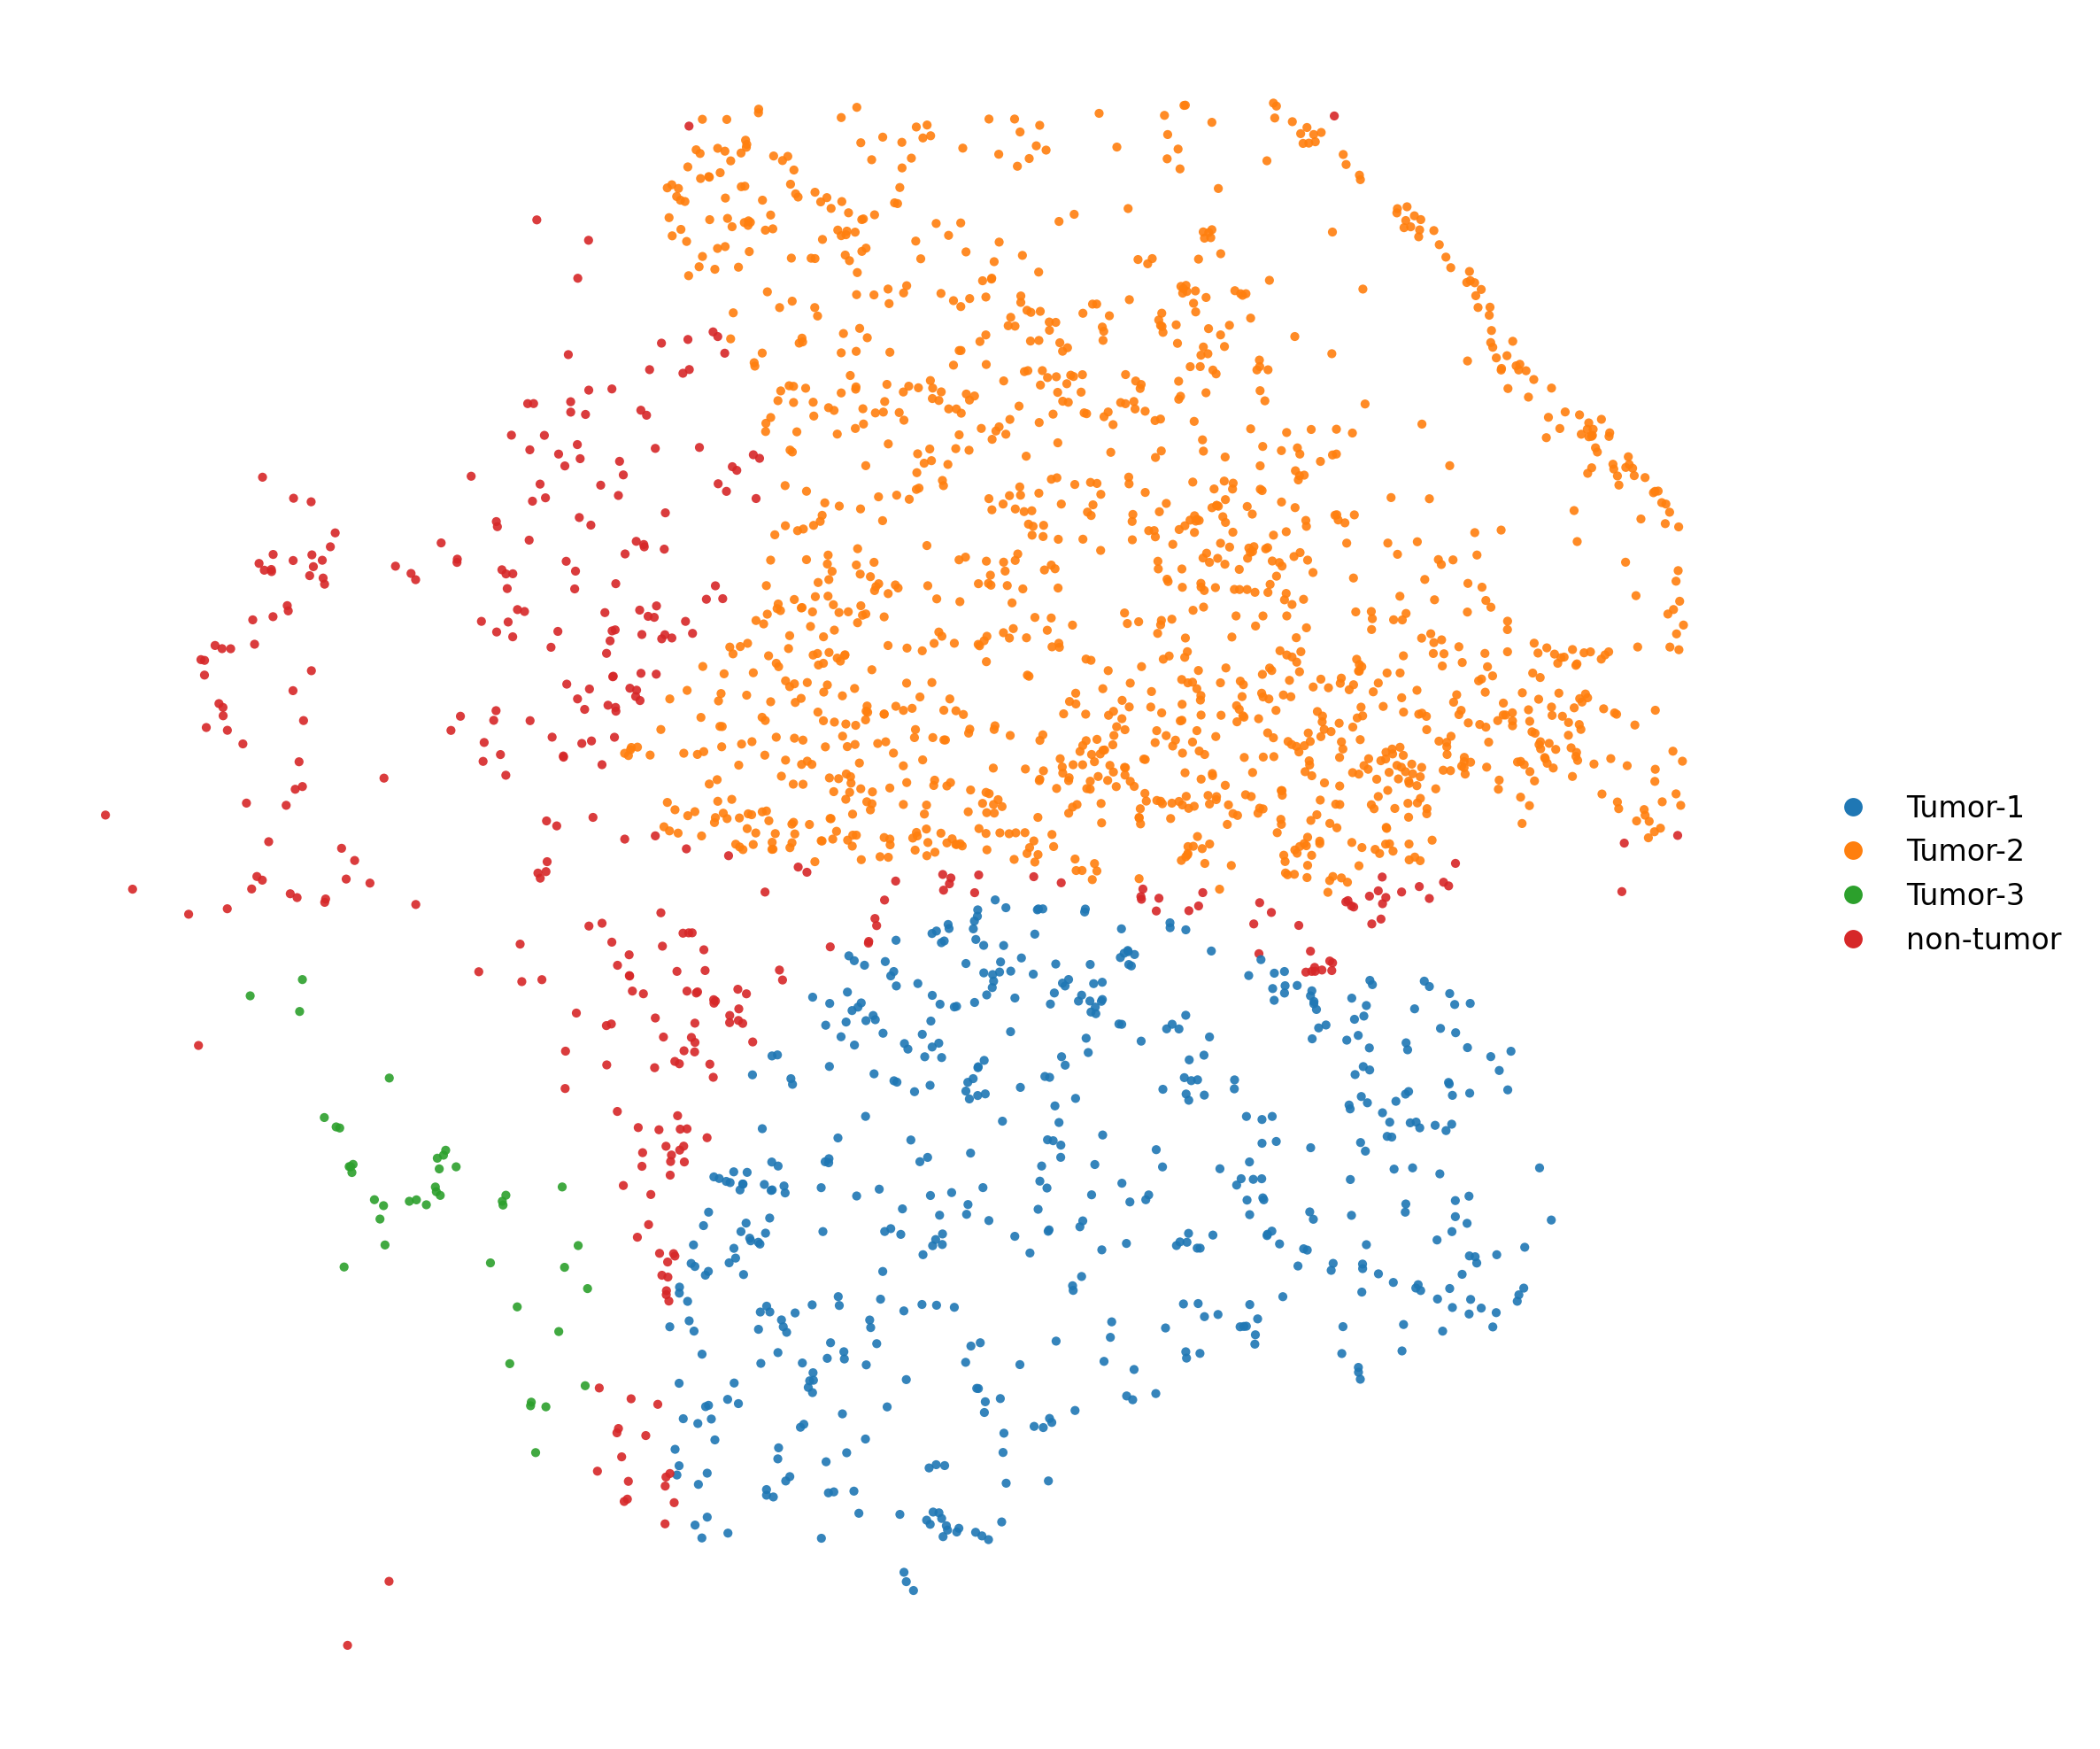

In [6]:

plot_show_spatial(adata, color_feature="tumor_id", size=6, alpha=0.9, output_dir=output_dir, spatial_key="spatial", invert_y=True, show_axis=False, figsize=(8, 8), legend_fontsize=8)

In [7]:
final_latent = np.loadtxt("final_latent.txt", delimiter=",")
gp_latent = np.loadtxt("gp_latent.txt", delimiter=",")
gp_S_latent = np.loadtxt("gp_S_latent.txt", delimiter=",")
gaussian_latent = np.loadtxt("gaussian_latent.txt", delimiter=",")


adata.obsm["DeepTracing_UV"] = final_latent
adata.obsm["DeepTracing_LV"] = gp_latent
adata.obsm["DeepTracing_SV"] = gp_S_latent
adata.obsm["DeepTracing_IV"] = gaussian_latent

PORCELAN_latent = np.load(Path(".KP_PORCELAN/results/Puck1_Layer1_latent_genes_PORCELAN_1000.npy"))
adata.obsm["PORCELAN"] = PORCELAN_latent

scVI_latent = np.loadtxt(
    Path("../results_scVI/scvi_latent_KP.txt"),
    delimiter=","
)
adata.obsm["scVI"] = scVI_latent

adata.obsm["PCA"] = adata.obsm["X_pca"]


Evaluating Cell Type Conservation (obs['cell_type'])...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s, Bio conservation: nmi_ari_cluster_labels_kmeans]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                        


Evaluating Lineage Conservation (obs['root_branch'])...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 7/7 [00:44<00:00,  6.38s/it]o conservation: silhouette_label]

                                                                                


Evaluating Tumor Type Conservation (obs['tumor_id'])...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 7/7 [00:13<00:00,  1.97s/it]o conservation: silhouette_label]

                                                                                

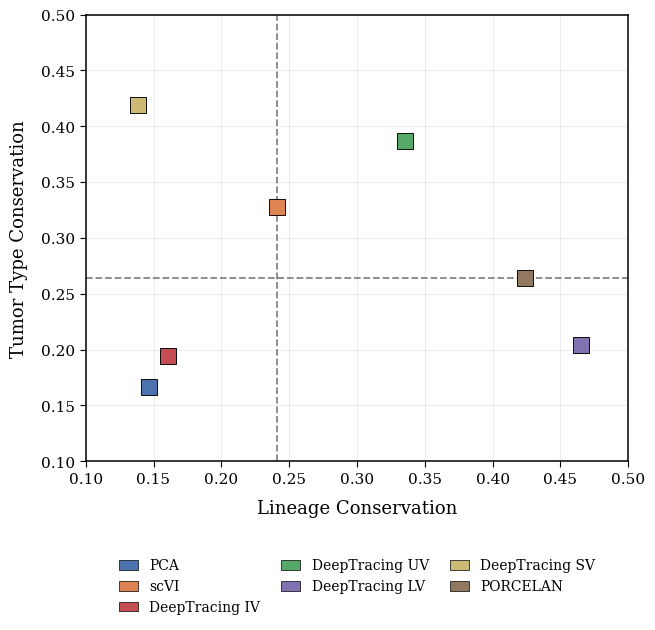

Lineage Conservation median=0.2410; Tumor Type Conservation median=0.2642
Saved: evalustion_metrics_results/Lineage_Conservation_vs_Tumor_Type_Conservation_scatter.svg and evalustion_metrics_results/Lineage_Conservation_vs_Tumor_Type_Conservation_scatter.pdf


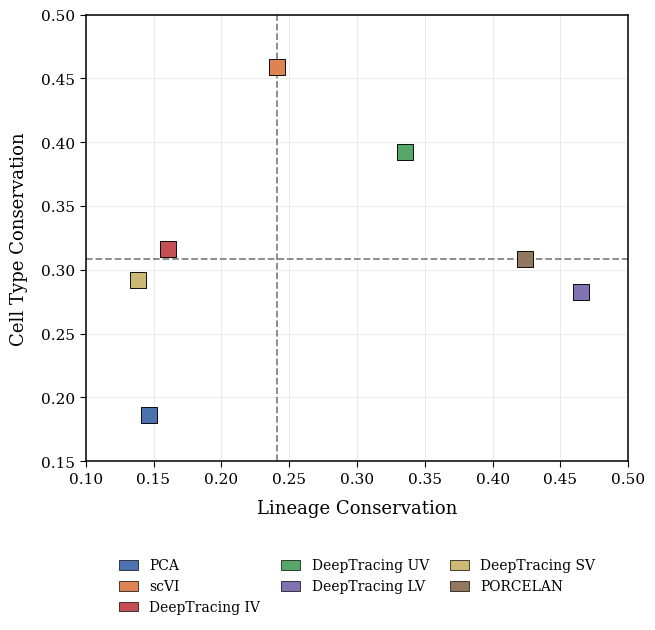

Lineage Conservation median=0.2410; Cell Type Conservation median=0.3087
Saved: evalustion_metrics_results/Lineage_Conservation_vs_Cell_Type_Conservation_scatter.svg and evalustion_metrics_results/Lineage_Conservation_vs_Cell_Type_Conservation_scatter.pdf


,Cell Type Conservation,Lineage Conservation,Tumor Type Conservation
Embedding,,,
PCA,0.1863,0.1465,0.1666
scVI,0.4593,0.2410,0.3281
DeepTracing_UV,0.3922,0.3354,0.3866
DeepTracing_LV,0.2825,0.4648,0.2045
DeepTracing_SV,0.2922,0.1385,0.4193
DeepTracing_IV,0.3161,0.1607,0.1942
PORCELAN,0.3087,0.4237,0.2642


In [8]:
full_metrics, summary_scores, benchmarkers, scatter_files = run_kp_scib(
    adata,
    output_dir="./evalustion_metrics_results",
    n_jobs=8,
    show=True,
)

display(summary_scores.round(4))